<small>Dataset: diabetes.csv</small>

# Q20. Diabetes KNN

Use nearby labeled examples to classify new records, and compare three K values.


## Question from Classroom

Diabetes Classification Using KNN 
Problem statement: Use KNN to classify records in a suitable public diabetes dataset. 
Tasks to be performed: 
1. Load the dataset and identify the target class. 
2. Inspect missing values, invalid zero values where applicable and feature 
distributions. 
3. Split the data using stratification where appropriate. 
4. Standardize the features using a training-fitted scaler. 
5. Train KNN models with different K values. 
6. Compare model performance using precision, recall, F1-score and confusion matrix.


## Understand before coding

Choose X/y -> stratified split -> training-only imputation and scaling -> compare K=3,5,7 -> print metrics and unseen predictions.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 6 listed tasks → 6 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load the dataset and identify the target class.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
df=pd.read_csv("data/diabetes.csv").dropna(subset=["Outcome"])
print("Target: Outcome")


Target: Outcome


## Task 2. Inspect missing values, invalid zero values where applicable and feature distributions.

This block implements the task above. Variables from earlier blocks are reused.


Shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  ...  Pedigree  Age  Outcome
0            6      148             72  ...     0.627   50        1
1            1       85             66  ...     0.351   31        0
2            8      183             64  ...     0.672   32        1
3            1       89             66  ...     0.167   21        0
4            0      137             40  ...     2.288   33        1

[5 rows x 9 columns]
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        7

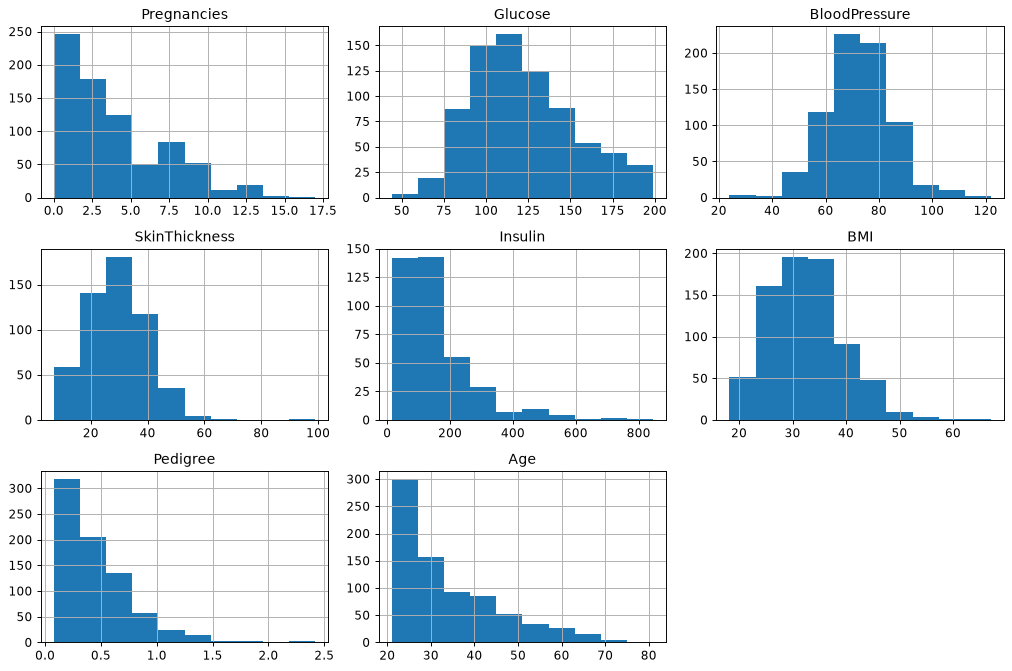

In [2]:
print("Shape:",df.shape)
print(df.head())
df.info()
print("Missing values:\n",df.isna().sum())
print("Summary:\n",df.describe(include="all").T)

zero_missing=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
df[zero_missing]=df[zero_missing].replace(0,np.nan)
X=df.drop(columns="Outcome")
y=df["Outcome"]
print("Missing after invalid-zero handling:",X.isna().sum().to_dict())
X.hist(figsize=(12,8));plt.tight_layout();plt.show()


## Task 3. Split the data using stratification where appropriate.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


## Task 4. Standardize the features using a training-fitted scaler.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
preprocessing=make_pipeline(SimpleImputer(strategy="median"),StandardScaler())
train_scaled=preprocessing.fit_transform(X_train)
test_scaled=preprocessing.transform(X_test)
print("Training shape after scaling:",train_scaled.shape)
print("In the next task, CV refits this same sequence inside each training fold.")


Training shape after scaling: (614, 8)
In the next task, CV refits this same sequence inside each training fold.


## Task 5. Train KNN models with different K values.

This block implements the task above. Variables from earlier blocks are reused.


In [5]:
models={}
results=[]
for k in [3,5,7]:
    model=make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),KNeighborsClassifier(n_neighbors=k))
    cv_accuracy=cross_val_score(model,X_train,y_train,cv=3,scoring="accuracy").mean()
    model.fit(X_train,y_train)
    models[k]=model
    results.append({"K":k,"Training CV accuracy":cv_accuracy,"Test accuracy":accuracy_score(y_test,model.predict(X_test))})
table=pd.DataFrame(results)


## Task 6. Compare model performance using precision, recall, F1-score and confusion matrix.

This block implements the task above. Variables from earlier blocks are reused.


In [6]:
print(table.to_string(index=False))
best_k=int(table.loc[table["Training CV accuracy"].idxmax(),"K"])
print("K selected using training CV:",best_k)
model=models[best_k]
prediction=model.predict(X_test)

for k,model in models.items():
    prediction=model.predict(X_test)
    print("K =",k)
    print(confusion_matrix(y_test,prediction))
    print(classification_report(y_test,prediction,zero_division=0))


 K  Training CV accuracy  Test accuracy
 3              0.726455       0.720779
 5              0.755739       0.753247
 7              0.741081       0.727273
K selected using training CV: 5
K = 3
[[78 22]
 [21 33]]
              precision    recall  f1-score   support

           0       0.79      0.78      0.78       100
           1       0.60      0.61      0.61        54

    accuracy                           0.72       154
   macro avg       0.69      0.70      0.69       154
weighted avg       0.72      0.72      0.72       154

K = 5
[[83 17]
 [21 33]]
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154

K = 7
[[82 18]
 [24 30]]
              precision    recall  f1-score   support

           0       0.77 

## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What does the confusion matrix contain?**

Rows are actual classes and columns are predicted classes, in the printed label order. For binary labels [0,1], it is [[TN,FP],[FN,TP]].

**10. Define accuracy, precision, recall and F1.**

Accuracy=(TP+TN)/N. Precision=TP/(TP+FP). Recall=TP/(TP+FN). F1=2PR/(P+R). classification_report prints per-class values and macro/weighted averages. zero_division=0 handles an undefined score.

**11. Why can accuracy be misleading?**

If most examples belong to one class, always predicting that class may give high accuracy. Inspect minority-class recall, precision, F1 and the confusion matrix.

**12. Why stratify=y?**

It approximately preserves class proportions in training and test splits. Each class needs enough examples.

**13. How does KNN classify a record?**

Measure distance to training examples, take the K nearest, and predict by their class votes.

**14. Why scale features?**

A large numeric range could dominate distance. StandardScaler subtracts the training mean and divides by training standard deviation.

**15. Why try K=3,5,7?**

The question requests multiple K values. They illustrate the bias/variance tradeoff; three candidates do not guarantee the best possible K.

**16. Why choose K by training CV?**

Repeatedly choosing the best final test score would make the test set part of tuning. We show the requested test comparisons but select K using training cross-validation.

**17. What if K is very small or large?**

Small K can follow noise and overfit. Very large K can smooth away useful local patterns and underfit.

**18. Does an odd K prevent every tie?**

No. It helps avoid a two-class even-vote tie, but multiclass votes can still tie.

**19. Is KNN eager or lazy?**

It is called lazy learning: it retains training examples and performs much of its work during prediction.

**20. What does the pipeline do?**

Impute training medians, fit a training scaler, then fit KNN. During CV each fold fits its own preprocessing, preventing leakage.

**21. Complexity?**

Brute-force prediction needs roughly O(n*p) distance work per query for n training rows and p features, plus neighbour selection. Storage is roughly O(n*p); indexed algorithms vary.

**22. Why replace some zeros?**

A zero Glucose, BloodPressure, SkinThickness, Insulin or BMI represents an invalid/missing measurement in this practice treatment. Zero Pregnancies is valid and is retained.

**23. What is Outcome?**

The supplied binary class label. This notebook predicts the dataset label as an educational exercise.


### Task-to-code map

- **Block 1:** Load the dataset and identify the target class.
- **Block 2:** Inspect missing values, invalid zero values where applicable and feature distributions.
- **Block 3:** Split the data using stratification where appropriate.
- **Block 4:** Standardize the features using a training-fitted scaler.
- **Block 5:** Train KNN models with different K values.
- **Block 6:** Compare model performance using precision, recall, F1-score and confusion matrix.
